# Fitting photometry and a spectrum together

This example fits a synthetic star three ways: with its spectrum, with its
SDSS colors, and with both together. The star is computed from the test grid
`phoenix_t4000_10000_w3000_9000_r3000.h5`, which covers 3000 to 9000 Å, so
the fitted values can be compared with the input ones. The fits use
MultiNest, which needs the pymultinest package and the MultiNest library
(see [Installation](../installation.rst) and [Fitting](../fitting.rst)); the
three fits take about half a minute in total.

In [1]:
import logging
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from astropy import units as u

from starkit import assemble_model
from starkit.fitkit.likelihoods import (Addition, PhotometryColorLikelihood,
                                        SpectralChi2Likelihood)
from starkit.fitkit.multinest import MultiNest
from starkit.fitkit.priors import UniformPrior
from starkit.fix_spectrum1d import SKSpectrum1D
from starkit.gridkit import load_grid

logging.getLogger('starkit').setLevel(logging.WARNING)
# The normalization warns about every full-rank polynomial fit (BUGS.md).
warnings.filterwarnings('ignore', message='The fit may be poorly conditioned')
# The flux unit label of the grid, erg/s/angstrom, has several slashes.
warnings.filterwarnings('ignore', message='.*contains multiple slashes')

## The synthetic star

The star has $T_\mathrm{eff}$ = 5780 K, $\log g$ = 4.4, [M/H] = -0.3, a
radial velocity of 25 km/s and an extinction $A_V$ = 0.5 mag
($R_V$ = 3.1).

In [2]:
grid = load_grid('phoenix_t4000_10000_w3000_9000_r3000.h5',
                 wavelength_type='vacuum')
truth = {'teff': 5780., 'logg': 4.4, 'mh': -0.3, 'vrad': 25., 'a_v': 0.5}
grid.teff, grid.logg, grid.mh = truth['teff'], truth['logg'], truth['mh']

The spectrum is made as in [Fitting](../fitting.rst): the model between 5000
and 5500 Å, shifted by the radial velocity, normalized to its median, with
Gaussian noise for a signal-to-noise ratio of 50 per pixel. The normalization
removes the continuum shape, so the spectrum carries no information on the
extinction.

In [3]:
wavelength, flux = assemble_model(grid, vrad=truth['vrad'])()
in_range = (wavelength > 5000) & (wavelength < 5500)
obs_wavelength = wavelength[in_range][::2]
obs_flux = np.interp(obs_wavelength, wavelength, flux)
obs_flux /= np.median(obs_flux)
obs_uncertainty = obs_flux / 50.
obs_flux += np.random.default_rng(0).normal(0., obs_uncertainty)
spectrum = SKSpectrum1D.from_array(
    wavelength=obs_wavelength * u.angstrom,
    flux=obs_flux * u.Unit('erg / (s cm2 Angstrom)'),
    uncertainty=obs_uncertainty)
print(f'{obs_wavelength.size} pixels from {obs_wavelength[0]:.1f} to '
      f'{obs_wavelength[-1]:.1f} Angstrom')

572 pixels from 5000.0 to 5499.3 Angstrom


The photometry is in the SDSS u, g, r and i filters, with curves from the SVO
Filter Profile Service. SDSS z is left out: 42% of its response lies beyond
the 9000 Å limit of the grid, and `Photometry` refuses a filter with more
than 1% of its response outside the spectrum. SDSS magnitudes are on the AB
system, so `mag_type='ab'`. The magnitudes are those of the reddened model,
with Gaussian noise of 0.02 mag.

The grid holds the flux at the stellar surface, so the magnitudes are those
of the stellar surface (see [Grid flux units](../io/flux_units.rst)). Their
differences, the colors, do not depend on the radius or the distance of the
star, and the fits below use only the colors.

In [4]:
sdss = ['SLOAN/SDSS.u', 'SLOAN/SDSS.g', 'SLOAN/SDSS.r', 'SLOAN/SDSS.i']
true_magnitudes = assemble_model(grid, filter_set=sdss, mag_type='ab',
                                 a_v=truth['a_v'])()
magnitude_uncertainties = np.full(len(sdss), 0.02)
observed_magnitudes = true_magnitudes + np.random.default_rng(1).normal(
    0., magnitude_uncertainties)
pd.DataFrame({'model': true_magnitudes, 'observed': observed_magnitudes,
              'uncertainty': magnitude_uncertainties},
             index=sdss).round(4)

,model,observed,uncertainty
SLOAN/SDSS.u,-36.1444,-36.1375,0.02
SLOAN/SDSS.g,-37.4879,-37.4715,0.02
SLOAN/SDSS.r,-38.0934,-38.0868,0.02
SLOAN/SDSS.i,-38.3133,-38.3394,0.02


## The likelihoods

Each likelihood is a model followed by a likelihood operation.

- The spectrum: `SpectralChi2Likelihood` compares the observed spectrum with
  the model, shifted by the radial velocity and normalized with a polynomial
  of degree 3.
- The colors: `PhotometryColorLikelihood` compares the colors u - g, g - r and
  r - i with those of the model, reddened with `a_v`.
- Both: `assemble_model` with a spectrum and `filter_set` sends the model
  spectrum both to the spectrograph operations and to `Photometry`. The two
  likelihood operations are joined with `&`, and `Addition` adds their
  logarithms. The extinction is applied to the magnitudes only.

`r_v` is a fixed parameter of the extinction, held at 3.1.

In [5]:
spectrum_likelihood = (
    assemble_model(grid, spectrum=spectrum, vrad=0., normalize_npol=3)
    | SpectralChi2Likelihood(spectrum))
color_likelihood = (
    assemble_model(grid, filter_set=sdss, mag_type='ab', a_v=0.)
    | PhotometryColorLikelihood(observed_magnitudes, magnitude_uncertainties))
combined_likelihood = (
    assemble_model(grid, spectrum=spectrum, filter_set=sdss, mag_type='ab',
                   vrad=0., a_v=0., normalize_npol=3)
    | (SpectralChi2Likelihood(spectrum)
       & PhotometryColorLikelihood(observed_magnitudes,
                                   magnitude_uncertainties))
    | Addition())
likelihoods = {'spectrum': spectrum_likelihood, 'colors': color_likelihood,
               'combined': combined_likelihood}


def free_parameters(likelihood):
    return [name for name in likelihood.param_names
            if not getattr(likelihood, name).fixed]


for name, likelihood in likelihoods.items():
    print(f'{name:9s}', free_parameters(likelihood))

spectrum  ['teff_0', 'logg_0', 'mh_0', 'vrad_1']
colors    ['teff_0', 'logg_0', 'mh_0', 'a_v_1']
combined  ['teff_0', 'logg_0', 'mh_0', 'vrad_1', 'a_v_5']


## The fits

MultiNest needs a prior for each free parameter, in the order of
`free_parameters`. The priors are uniform: over the grid for
$T_\mathrm{eff}$, $\log g$ and [M/H], from -100 to 100 km/s for the radial
velocity, and from 0 to 3 mag for $A_V$. The seed makes the fits
reproducible.

In [6]:
grid_priors = dict(zip(grid.param_names, grid.get_grid_uniform_priors()))
other_priors = {'vrad': UniformPrior(-100., 100.), 'a_v': UniformPrior(0., 3.)}


def base_name(parameter):
    # teff_0 -> teff, a_v_4 -> a_v
    return parameter[:parameter.rfind('_')]


def priors_for(likelihood):
    priors = []
    for parameter in free_parameters(likelihood):
        name = base_name(parameter)
        priors.append(grid_priors[name] if name in grid_priors
                      else other_priors[name])
    return priors


results = {}
for name, likelihood in likelihoods.items():
    start = time.time()
    fitter = MultiNest(likelihood, priors_for(likelihood))
    results[name] = fitter.run(seed=1)
    print(f'{name:9s} {time.time() - start:5.0f} s')

 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    4
 *****************************************************


 ln(ev)=  -297.26116969113650      +/-  0.15865374635665447     
 Total Likelihood Evaluations:         9928
 Sampling finished. Exiting MultiNest
spectrum      2 s
 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    4
 *****************************************************


 ln(ev)=  -5.3855814487538884      +/-  0.10439055347789922     
 Total Likelihood Evaluations:         4787
 Sampling finished. Exiting MultiNest
colors        8 s
 MultiNest Warning: no resume file found, starting from scratch
 *****************************************************
 MultiNest v3.10
 Copyright Farhan Feroz & Mike Hobson
 Release Jul 2015

 no. of live points =  400
 dimensionality =    5
 *****************************************************


 ln(ev)=  -301.12962956347042      +/-  0.17612236924192665     
 Total Likelihood Evaluations:        13669
 Sampling finished. Exiting MultiNest
combined     21 s


## Results

The table gives the median of each posterior and, after it, the distances
from the median to the upper and lower limits of the central 68% of the
posterior.

In [7]:
labels = {'teff': 'Teff (K)', 'logg': 'log g', 'mh': '[M/H]',
          'vrad': 'v_rad (km/s)', 'a_v': 'A_V (mag)'}
digits = {'teff': 0, 'logg': 2, 'mh': 3, 'vrad': 2, 'a_v': 3}


def posterior_column(result, name):
    columns = [c for c in result.parameter_names if base_name(c) == name]
    return columns[0] if columns else None


rows = {}
for name, label in labels.items():
    row = {'input': f'{truth[name]:.{digits[name]}f}'}
    for fit, result in results.items():
        column = posterior_column(result, name)
        if column is None:
            row[fit] = ''
            continue
        median = result.median[column]
        lower, upper = result.calculate_sigmas(1)[column]
        row[fit] = (f'{median:.{digits[name]}f} '
                    f'+{upper - median:.{digits[name]}f} '
                    f'-{median - lower:.{digits[name]}f}')
    rows[label] = row
pd.DataFrame(rows).T

,input,spectrum,colors,combined
Teff (K),5780,5718 +70 -75,6051 +579 -479,5725 +77 -73
log g,4.40,4.29 +0.15 -0.13,4.24 +0.53 -0.73,4.32 +0.15 -0.14
[M/H],-0.300,-0.313 +0.055 -0.059,-0.596 +0.302 -0.238,-0.318 +0.055 -0.060
v_rad (km/s),25.00,25.19 +2.25 -2.23,,25.47 +2.15 -2.27
A_V (mag),0.500,,0.820 +0.319 -0.370,0.478 +0.074 -0.078


The spectrum alone gives $T_\mathrm{eff}$ = 5718 +70 -75 K, $\log g$ = 4.29
+0.15 -0.13, [M/H] = -0.313 +0.055 -0.059 and a radial velocity of 25.19
+2.25 -2.23 km/s; the input values lie within these 68% intervals. It gives
no information on the extinction, because it is normalized.

The colors alone give $T_\mathrm{eff}$ = 6051 +579 -479 K and
$A_V$ = 0.820 +0.319 -0.370 mag, and leave $\log g$ and [M/H] nearly
unconstrained: their posteriors spread over most of the grid. $T_\mathrm{eff}$
and $A_V$ are correlated (lower right panel of the posterior figure below),
because a hotter star behind more extinction has nearly the same colors.

Fitting both gives $A_V$ = 0.478 +0.074 -0.078 mag, a 68% interval of 0.15 mag
against 0.69 mag from the colors alone, while $T_\mathrm{eff}$ = 5725 +77 -73 K,
$\log g$ = 4.32 +0.15 -0.14 and [M/H] = -0.318 +0.055 -0.060 are set by the
spectrum. The input values of all five parameters lie within the 68%
intervals.
MultiNest made 9928, 4787 and 13669 likelihood evaluations for the spectrum,
colors and combined fits.

The extinction law is the same in the synthetic data and in the fits (CCM89,
$R_V$ = 3.1). With observed data, a different law biases $A_V$ and, through
the colors, $T_\mathrm{eff}$.


In [8]:
FONT_KW = {'legend.fontsize': 13, 'font.size': 14, 'axes.titlesize': 15,
           'axes.labelsize': 14, 'xtick.labelsize': 14, 'ytick.labelsize': 14,
           'figure.titlesize': 16}
plt.rcParams.update(FONT_KW)
FIT_STYLE = {'spectrum': dict(color='tab:blue', label='spectrum only'),
             'colors': dict(color='tab:orange', label='colors only'),
             'combined': dict(color='tab:green', label='spectrum and colors')}


def model_at_median(fit, **keywords):
    """assemble_model(grid, **keywords) with the parameters at the medians
    of a fit; parameters the fit does not have keep the values in keywords."""
    model = assemble_model(grid, **keywords)
    median = results[fit].median
    for parameter in model.param_names:
        name = base_name(parameter)
        column = posterior_column(results[fit], name)
        if column is not None:
            setattr(model, parameter, median[column])
    return model

The observed spectrum and the model at the medians of the combined fit:

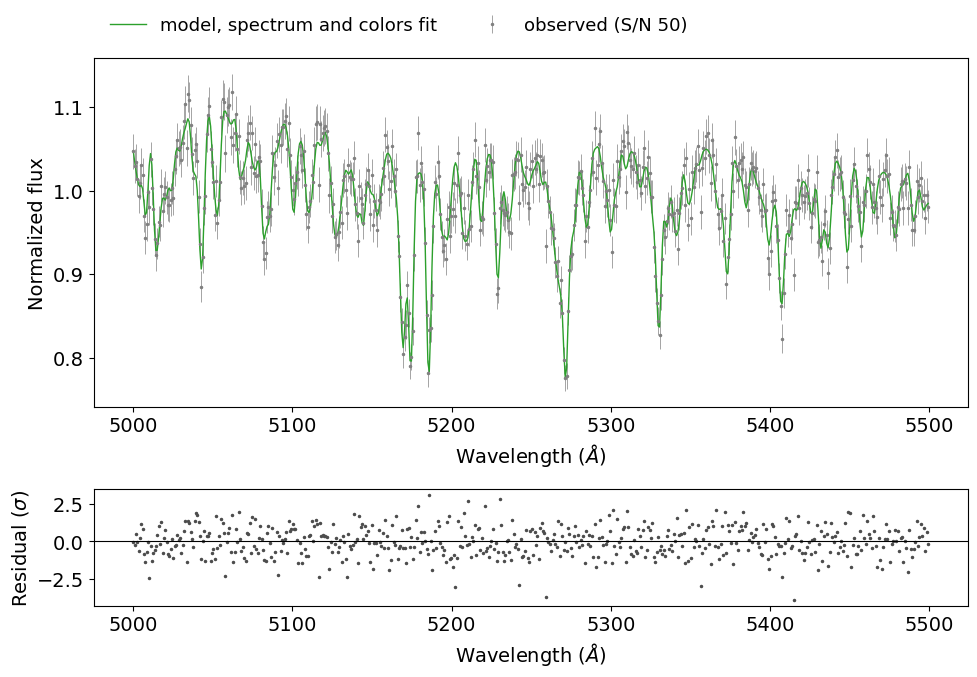

In [9]:
best = model_at_median('combined', spectrum=spectrum, filter_set=sdss,
                       mag_type='ab', vrad=0., a_v=0., normalize_npol=3)
model_wavelength, model_flux, model_magnitudes = best()

fig, (ax, ax_residual) = plt.subplots(
    2, 1, figsize=(10, 7), sharex=True, height_ratios=[3, 1])
ax.errorbar(obs_wavelength, obs_flux, obs_uncertainty, fmt='.', color='0.5',
            ms=3, lw=0.5, label='observed (S/N 50)')
ax.plot(model_wavelength, model_flux, color='tab:green', lw=1,
        label='model, spectrum and colors fit')
ax.set_ylabel('Normalized flux')
ax.legend(loc='lower left', bbox_to_anchor=(0, 1.02), ncol=2, frameon=False)
ax_residual.plot(obs_wavelength, (obs_flux - model_flux) / obs_uncertainty,
                 '.', color='0.3', ms=3)
ax_residual.axhline(0, color='black', lw=0.8)
ax_residual.set_xlabel(r'Wavelength ($\AA$)')
ax_residual.set_ylabel(r'Residual ($\sigma$)')
ax.tick_params(labelbottom=True)
ax.set_xlabel(r'Wavelength ($\AA$)')
fig.tight_layout()

The observed colors and those of the model at the medians of each fit. The
spectrum-only fit has no extinction, so its colors are those of the
unreddened model.

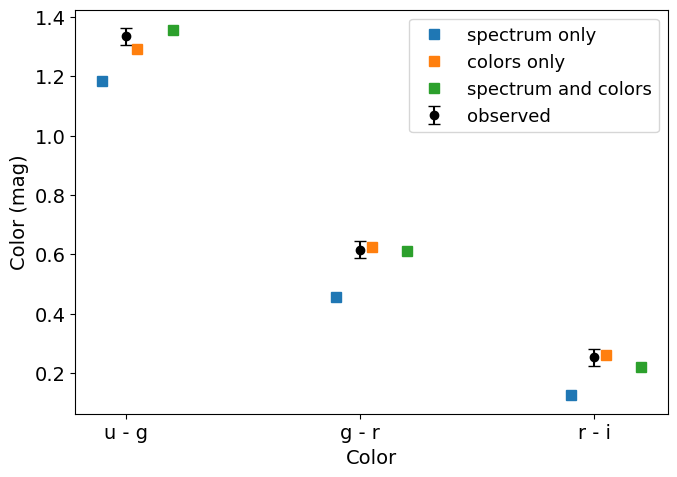

In [10]:
def colors(magnitudes):
    return np.asarray(magnitudes)[:-1] - np.asarray(magnitudes)[1:]


color_names = ['u - g', 'g - r', 'r - i']
x = np.arange(len(color_names))
fig, ax = plt.subplots(figsize=(7, 5))
ax.errorbar(x, colors(observed_magnitudes),
            np.sqrt(2) * magnitude_uncertainties[1:], fmt='o', color='black',
            capsize=4, label='observed')
for offset, fit in zip([-0.15, 0.0, 0.15], results):
    model = model_at_median(fit, filter_set=sdss, mag_type='ab', a_v=0.)
    ax.plot(x + offset + 0.05, colors(model()), 's', ms=7,
            **FIT_STYLE[fit])
ax.set_xticks(x)
ax.set_xticklabels(color_names)
ax.set_xlabel('Color')
ax.set_ylabel('Color (mag)')
ax.legend()
fig.tight_layout()

The posterior distributions of the three fits, with the input values as
vertical lines, and 2000 samples of $T_\mathrm{eff}$ and $A_V$ drawn from the
posteriors of the colors-only and combined fits:

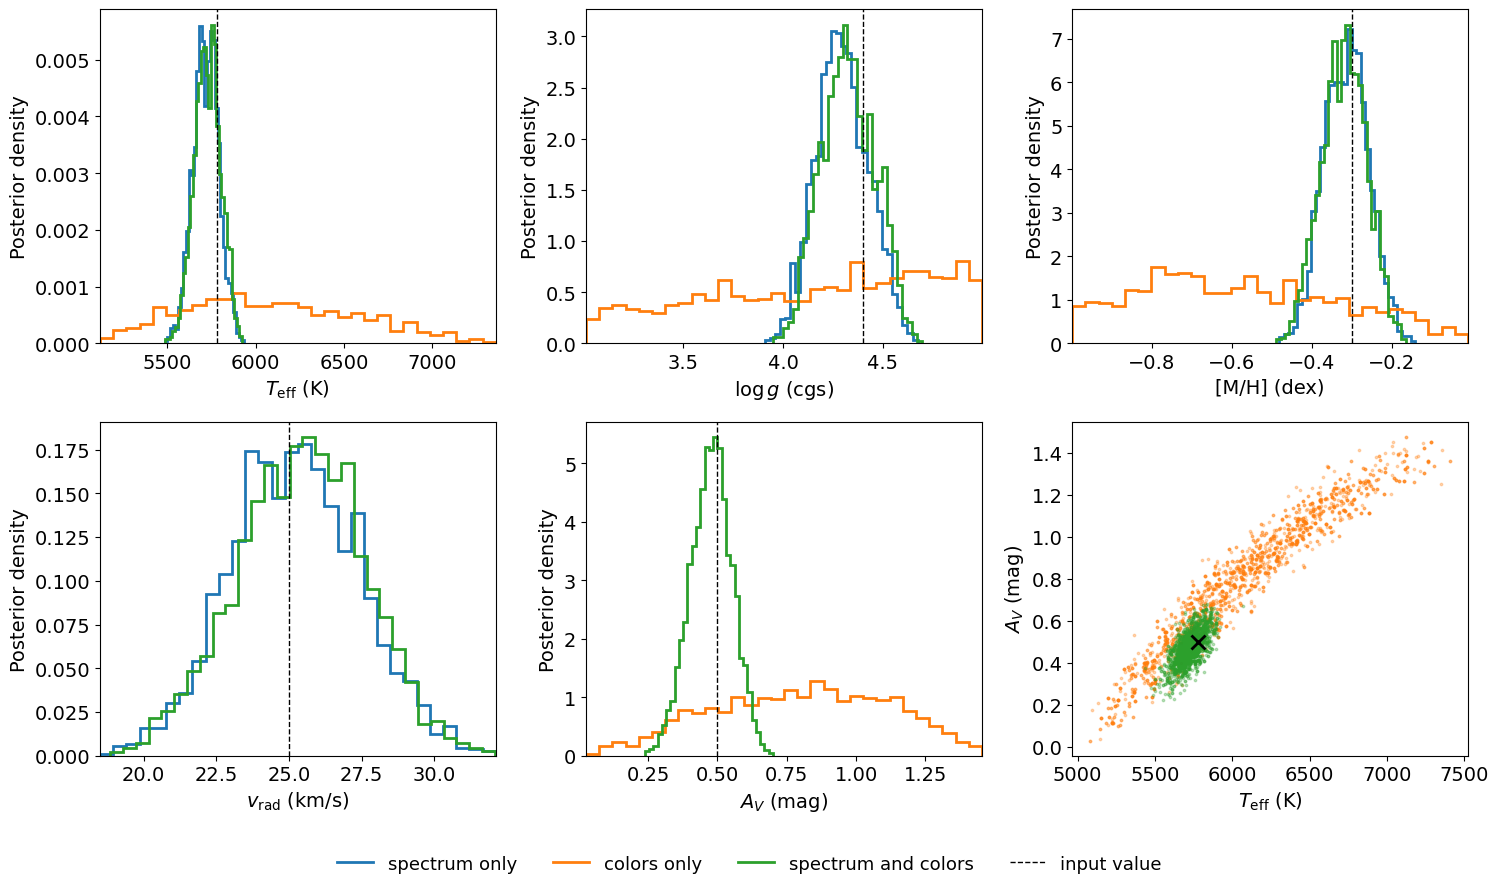

In [11]:
axis_labels = {'teff': r'$T_\mathrm{eff}$ (K)', 'logg': r'$\log g$ (cgs)',
               'mh': '[M/H] (dex)', 'vrad': r'$v_\mathrm{rad}$ (km/s)',
               'a_v': r'$A_V$ (mag)'}
def weighted_quantiles(values, weights, quantiles):
    order = np.argsort(values)
    cumulative = np.cumsum(np.asarray(weights)[order])
    return np.interp(quantiles, cumulative / cumulative[-1],
                     np.asarray(values)[order])


fig, axes = plt.subplots(2, 3, figsize=(15, 9))
for ax, name in zip(axes.flat, labels):
    limits = []
    for fit, result in results.items():
        column = posterior_column(result, name)
        if column is not None:
            data = result.posterior_data
            limits.extend(weighted_quantiles(data[column], data['weights'],
                                             [0.001, 0.999]))
    ax.set_xlim(min(limits), max(limits))
    for fit, result in results.items():
        column = posterior_column(result, name)
        if column is None:
            continue
        data = result.posterior_data
        low, high = weighted_quantiles(data[column], data['weights'],
                                       [0.001, 0.999])
        ax.hist(data[column], bins=np.linspace(low, high, 31),
                weights=data['weights'], density=True, histtype='step', lw=2,
                color=FIT_STYLE[fit]['color'])
    ax.axvline(truth[name], color='black', ls='--', lw=1)
    ax.set_xlabel(axis_labels[name])
    ax.set_ylabel('Posterior density')
ax = axes.flat[5]
rng = np.random.default_rng(2)
for fit in ['colors', 'combined']:
    # 2000 samples drawn with the posterior weights
    data = results[fit].posterior_data
    rows = rng.choice(len(data), size=2000,
                      p=data['weights'] / data['weights'].sum())
    ax.scatter(data[posterior_column(results[fit], 'teff')].iloc[rows],
               data[posterior_column(results[fit], 'a_v')].iloc[rows], s=3,
               alpha=0.3, color=FIT_STYLE[fit]['color'])
ax.plot(truth['teff'], truth['a_v'], 'x', color='black', ms=10, mew=2)
ax.set_xlabel(axis_labels['teff'])
ax.set_ylabel(axis_labels['a_v'])
handles = [plt.Line2D([], [], color=style['color'], lw=2, label=style['label'])
           for style in FIT_STYLE.values()]
handles.append(plt.Line2D([], [], color='black', ls='--', lw=1,
                          label='input value'))
fig.legend(handles=handles, loc='lower center', ncol=4, frameon=False)
fig.tight_layout(rect=[0, 0.06, 1, 1])